# Assignment #4

Write a program to enhance the “flower1.jpg” and “animals.jpg” images in frequency domain using the
following filters:

Notch filters:

1. Low-pass filter with radius, $𝑟$ equals to 10, 50, and 100, respectively.
$$
\begin{equation}
H(𝑢, 𝑣) =
\begin{cases}
1 & \text{if } (𝑢, 𝑣) \text{ is closer to the center than } 𝑟 \\
0 & \text{if } (𝑢, 𝑣) \text{ is further from the center than } 𝑟
\end{cases}
\end{equation}
$$

2. High-pass filter with radius, $𝑟$ equals to 10, 50, and 100, respectively.

$$
\begin{equation}
𝐻(𝑢, 𝑣) = 
\begin{cases}
0 & \text{if } (𝑢, 𝑣) \text{ is closer to the center than } 𝑟 \\
1 & \text{if } (𝑢, 𝑣) \text{ is further from the center than } 𝑟
\end{cases}
\end{equation}
$$

In [2]:
!uv add Pillow numpy matplotlib pandas opencv-python

Resolved 46 packages in 2ms
Checked 14 packages in 0.84ms


In [3]:
from matplotlib import pyplot as plt
import cv2

# load images
flower1 = cv2.imread('flower1.jpg')
animals = cv2.imread('animals.jpg')

In [4]:
import numpy as np

def distance_grid(shape):
    """D(u, v): distance of every (u, v) from the center of the (shifted) spectrum."""
    rows, cols = shape[:2]
    u = np.arange(rows) - rows / 2
    v = np.arange(cols) - cols / 2
    V, U = np.meshgrid(v, u)
    return np.sqrt(U ** 2 + V ** 2)

def ideal_lowpass_mask(shape, radius):
    return (distance_grid(shape) <= radius).astype(np.float32)

def ideal_highpass_mask(shape, radius):
    return 1.0 - ideal_lowpass_mask(shape, radius)

def apply_frequency_filter(image, H, normalize=False):
    """Apply mask H in the frequency domain to each channel of a BGR image."""
    out = np.zeros(image.shape, dtype=np.float32)
    for ch in range(image.shape[2]):
        F = np.fft.fftshift(np.fft.fft2(image[:, :, ch].astype(np.float32)))
        out[:, :, ch] = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))
    if normalize:
        # high-pass output is centered around 0 -> stretch magnitude to 0..255 for display
        out = cv2.normalize(np.abs(out), None, 0, 255, cv2.NORM_MINMAX)
    return np.clip(out, 0, 255).astype(np.uint8)

def lowpass_filter(image, radius):
    return apply_frequency_filter(image, ideal_lowpass_mask(image.shape, radius))

def highpass_filter(image, radius):
    return apply_frequency_filter(image, ideal_highpass_mask(image.shape, radius), normalize=True)

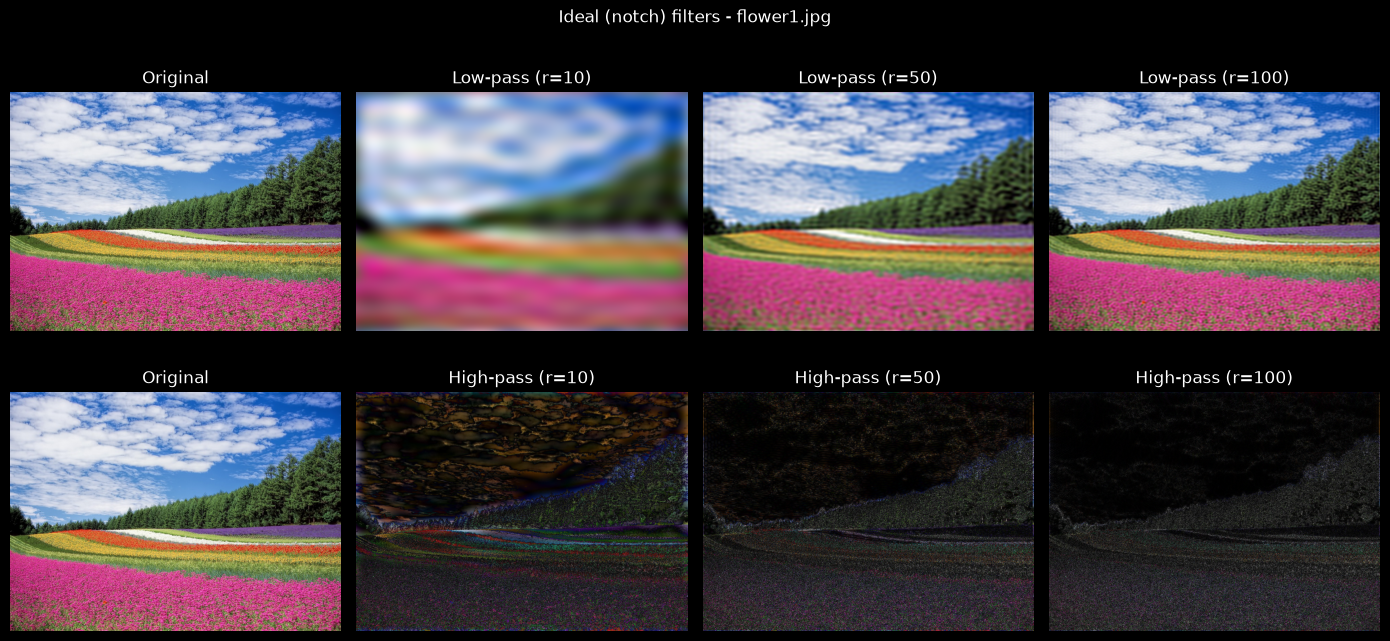

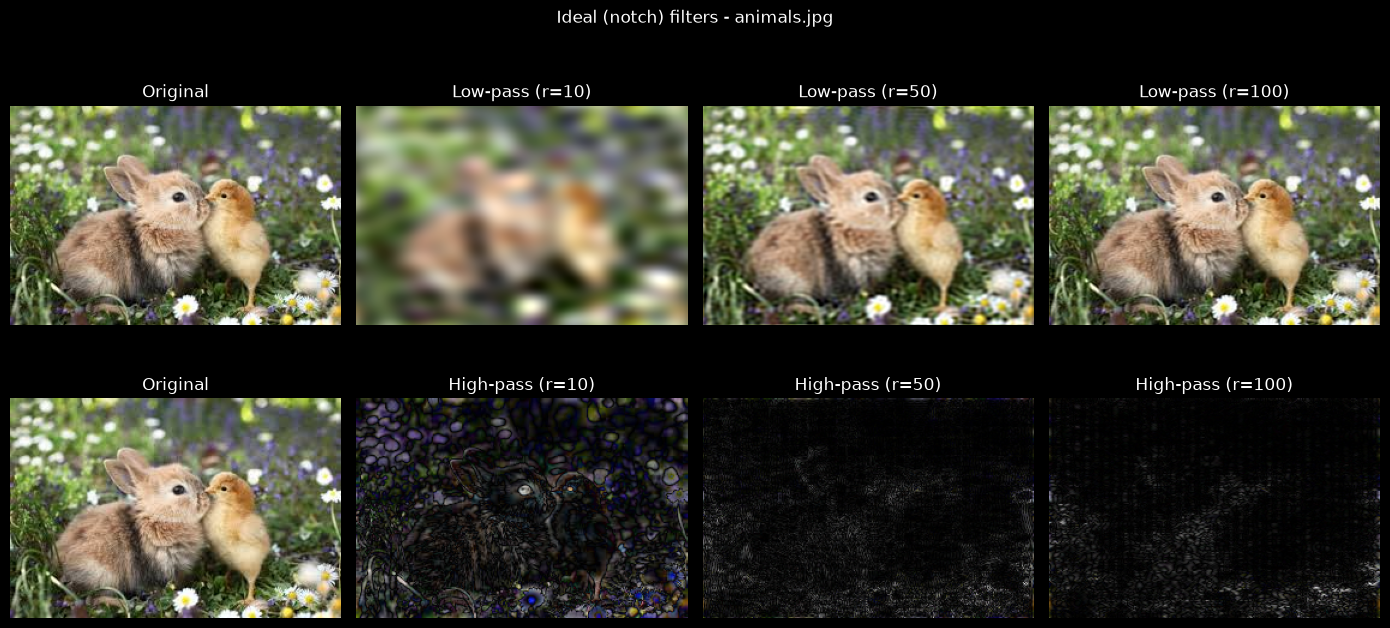

In [5]:
radiuses = [10, 50, 100]
images = {'flower1.jpg': flower1, 'animals.jpg': animals}

def show(img, title):
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')

base_size = 3.5
n_cols = len(radiuses) + 1  # original + one column per radius

for name, img in images.items():
    # row 1: original + low-pass, row 2: original + high-pass
    plt.figure(figsize=(base_size * n_cols, base_size * 2))
    plt.suptitle(f'Ideal (notch) filters - {name}')

    plt.subplot(2, n_cols, 1)
    show(img, 'Original')
    plt.subplot(2, n_cols, n_cols + 1)
    show(img, 'Original')

    for i, radius in enumerate(radiuses):
        plt.subplot(2, n_cols, i + 2)
        show(lowpass_filter(img, radius), f'Low-pass (r={radius})')

        plt.subplot(2, n_cols, n_cols + i + 2)
        show(highpass_filter(img, radius), f'High-pass (r={radius})')

    plt.tight_layout()
    plt.show()

Gaussian filters:
1. Low-pass filter with cutoff, $D_0$ equals to 10, 50, and 100, respectively.
$$
H(u, v) = e^{-D^2(u,v)/2D_0^2}
$$

2. High-pass filter with cutoff, $D_0$ equals to 10, 50, and 100, respectively.
$$
H(u, v) = 1 - e^{-D^2(u,v)/2D_0^2}
$$

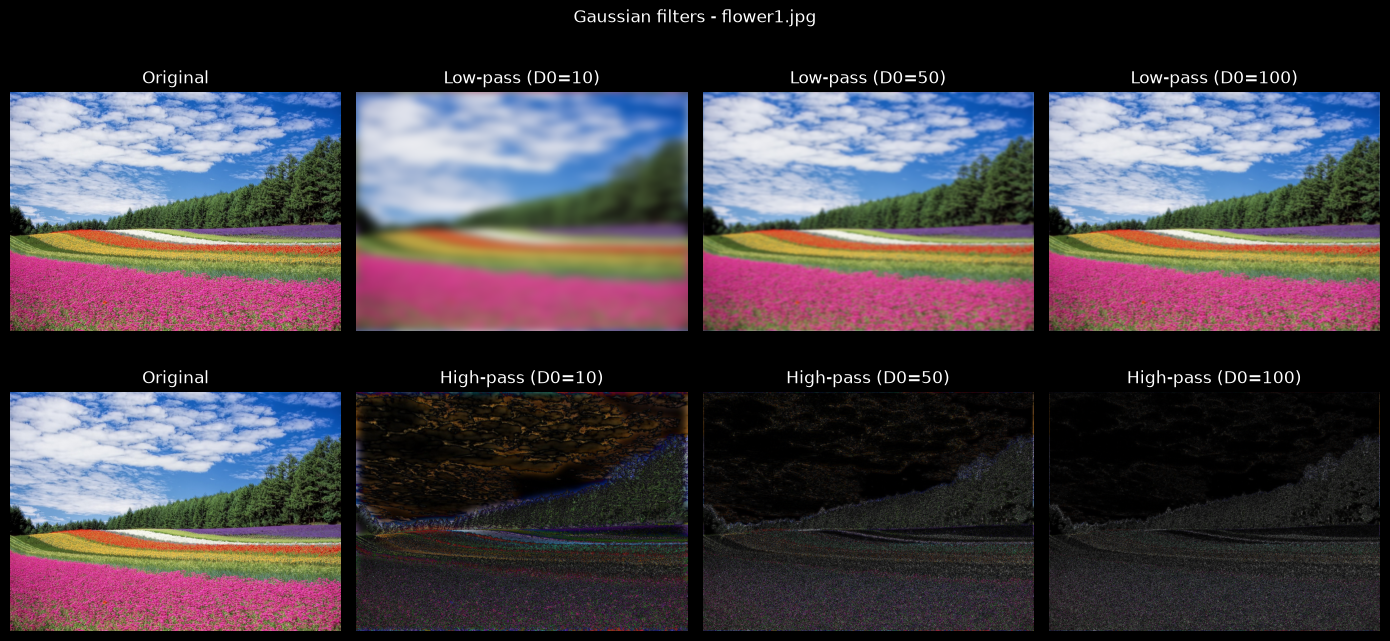

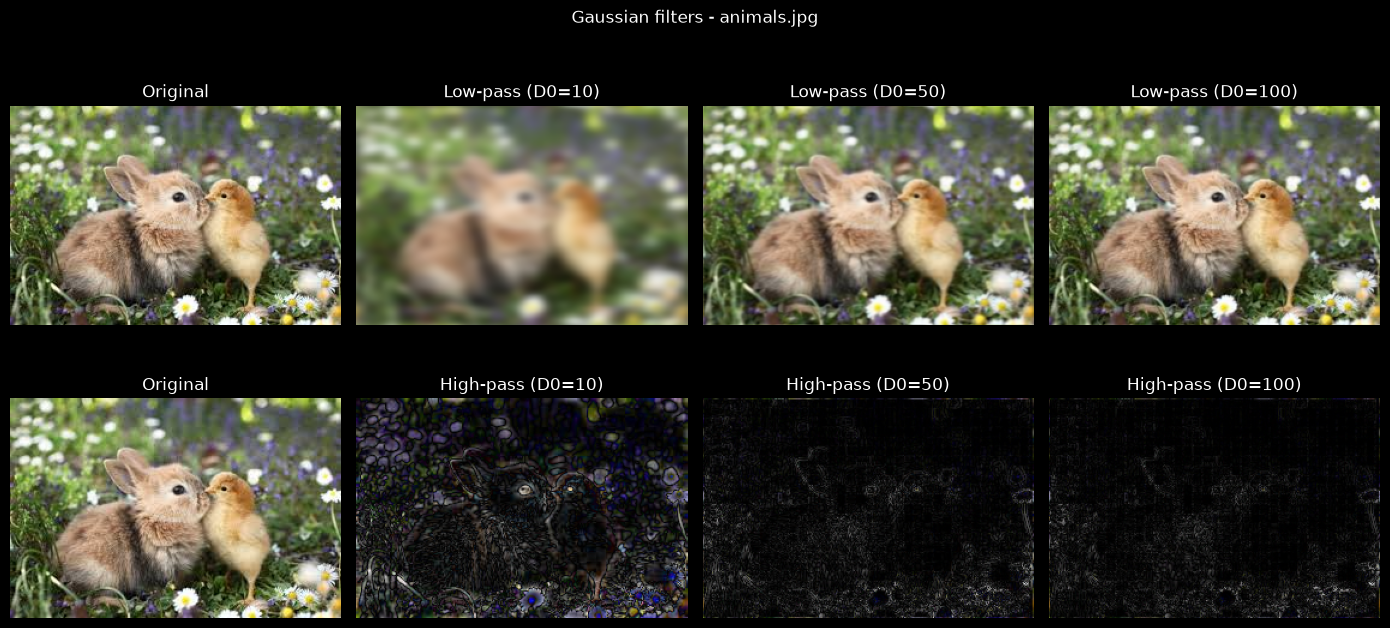

In [6]:
radiuses = [10, 50, 100]
images = {'flower1.jpg': flower1, 'animals.jpg': animals}

def show(img, title):
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    

base_size = 3.5
n_cols = len(radiuses) + 1  # original + one column per radius

def gaussian_lowpass_mask(shape, D0):
    """Gaussian low-pass filter mask."""
    D = distance_grid(shape)
    return np.exp(-(D ** 2) / (2 * (D0 ** 2)))
  
def gaussian_highpass_mask(shape, D0):
    """Gaussian high-pass filter mask."""
    return 1.0 - gaussian_lowpass_mask(shape, D0)

for name, img in images.items():
    # row 1: original + low-pass, row 2: original + high-pass
    plt.figure(figsize=(base_size * n_cols, base_size * 2))
    plt.suptitle(f'Gaussian filters - {name}')

    plt.subplot(2, n_cols, 1)
    show(img, 'Original')
    plt.subplot(2, n_cols, n_cols + 1)
    show(img, 'Original')

    for i, radius in enumerate(radiuses):
        plt.subplot(2, n_cols, i + 2)
        show(apply_frequency_filter(img, gaussian_lowpass_mask(img.shape, radius)), f'Low-pass (D0={radius})')

        plt.subplot(2, n_cols, n_cols + i + 2)
        show(apply_frequency_filter(img, gaussian_highpass_mask(img.shape, radius), normalize=True), f'High-pass (D0={radius})')

    plt.tight_layout()
    plt.show()

## 3. Periodic noise removal

noisy_flower1_horizontal.jpg: 2 notch pairs, D0=3
   centers (u, v) [+ mirror]: [(-139, 0), (-69, 0)]


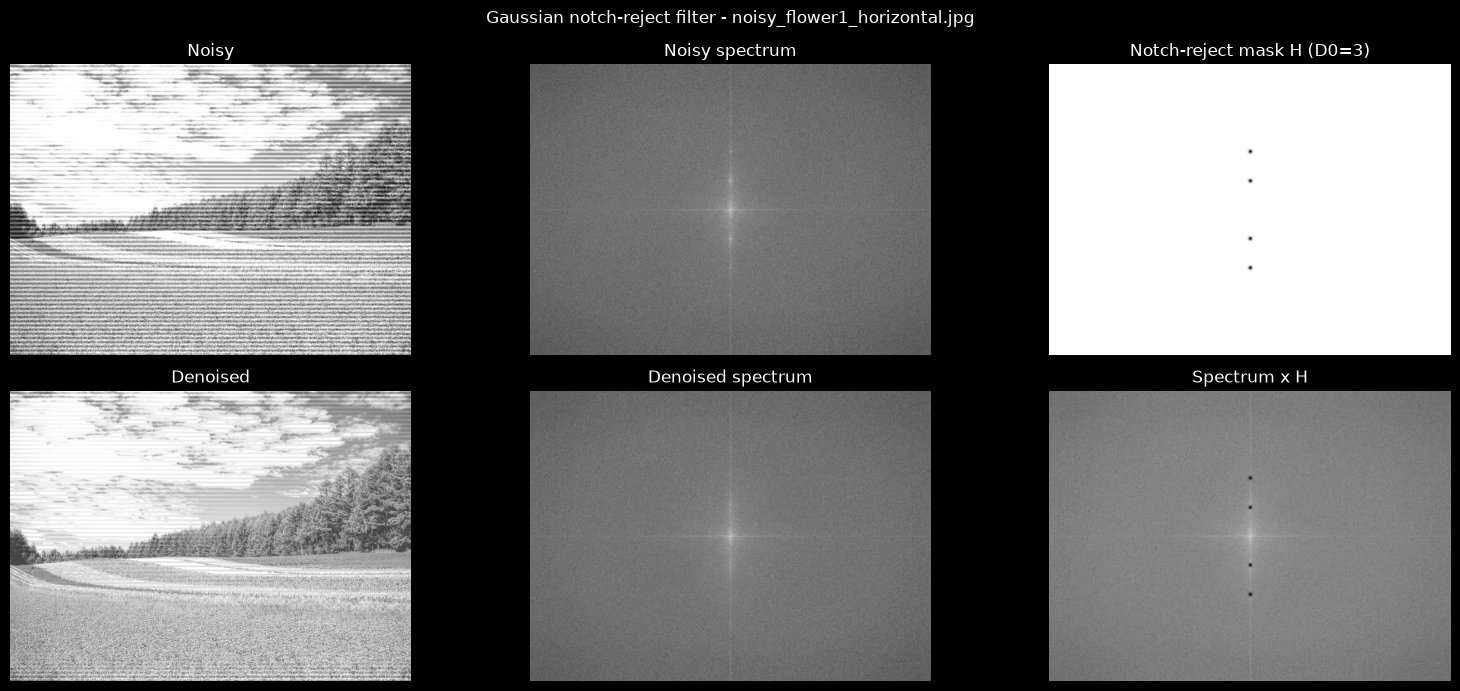

noisy_flower1_vertical.jpg: 2 notch pairs, D0=3
   centers (u, v) [+ mirror]: [(0, -192), (0, -96)]


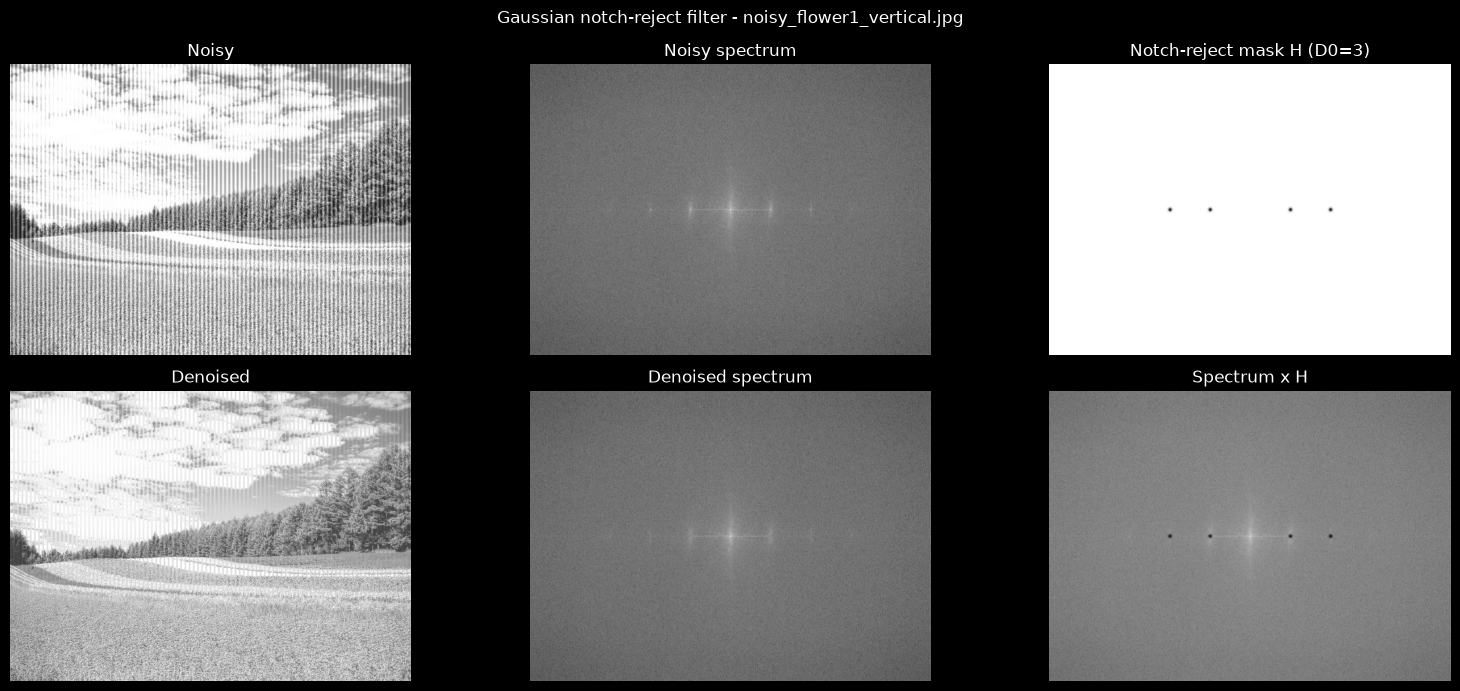

noisy_animals.jpg: 39 notch pairs, D0=3
   centers (u, v) [+ mirror]: [(-140, 28), (-139, -28), (-130, 28), (-121, -28), (-112, -28), (-111, 0), (-111, 28), (-108, 0), (-107, 181), (-103, 28), (-102, -28), (-101, 0), '...']


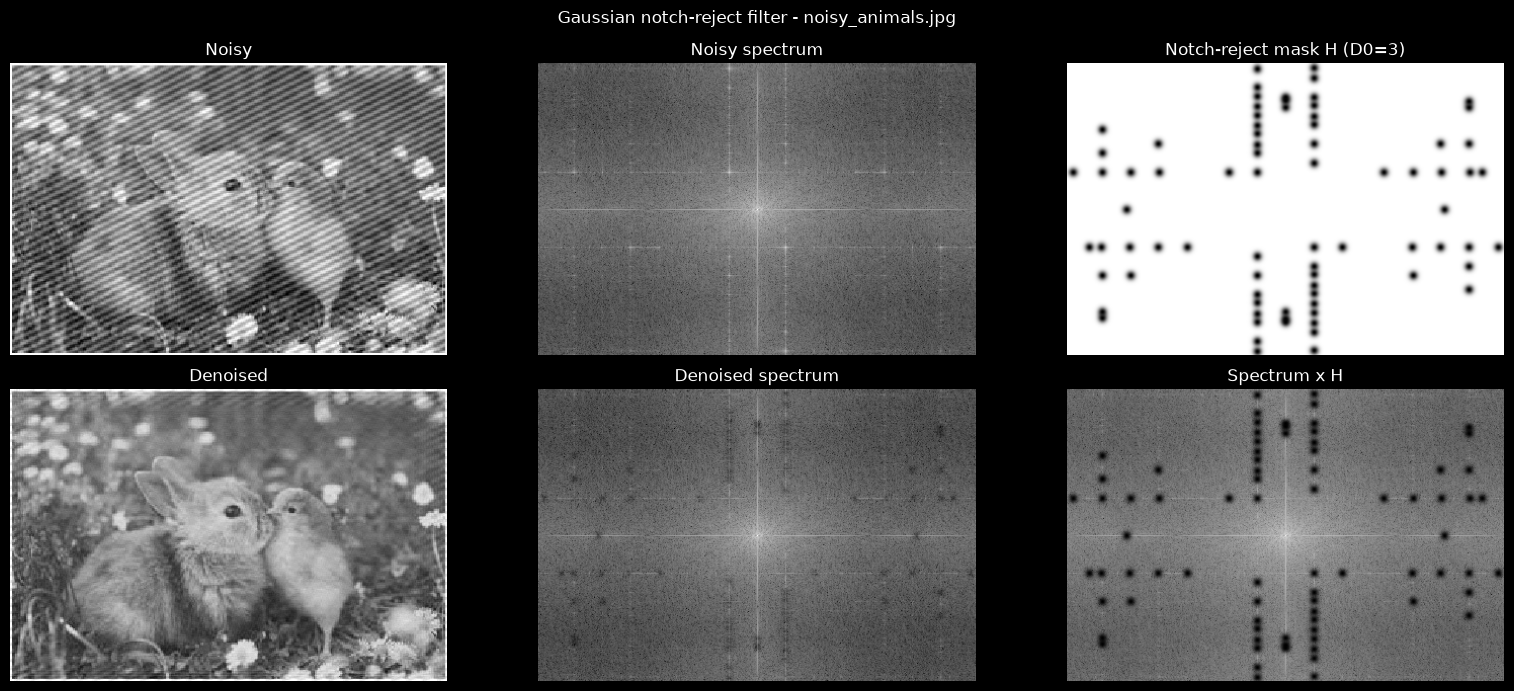

In [8]:
def log_spectrum(gray):
    F = np.fft.fftshift(np.fft.fft2(gray.astype(np.float32)))
    return np.log1p(np.abs(F)).astype(np.float32)

def find_noise_peaks(gray, protect_radius=10, bg_size=15, threshold=2.5, nms_size=5):
    # Find periodic-noise spikes (relative to the spectrum center) in a grayscale image.
    M = log_spectrum(gray)
    P = M - cv2.blur(M, (bg_size, bg_size))        # prominence above local background
    P[distance_grid(gray.shape) < protect_radius] = 0  # keep low frequencies untouched
    is_peak = (P == cv2.dilate(P, np.ones((nms_size, nms_size)))) & (P > threshold)
    rows, cols = gray.shape
    ys, xs = np.nonzero(is_peak)
    # keep one of each symmetric pair; the notch filter adds the mirror automatically
    peaks = {tuple(sorted([(int(y - rows // 2), int(x - cols // 2)), (int(rows // 2 - y), int(cols // 2 - x))])[0])
             for y, x in zip(ys, xs)}
    return sorted(peaks)

def gaussian_notch_reject_mask(shape, centers, D0):
    rows, cols = shape[:2]
    V, U = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    H = np.ones((rows, cols), dtype=np.float32)
    for (uk, vk) in centers:
        for s in (1, -1):  # notch at (uk, vk) and its symmetric partner (-uk, -vk)
            Dk2 = (U - s * uk) ** 2 + (V - s * vk) ** 2
            H *= 1 - np.exp(-Dk2 / (2 * D0 ** 2))
    return H

NOTCH_D0 = 3
noisy_images = {
    'noisy_flower1_horizontal.jpg': cv2.imread('noisy_flower1_horizontal.jpg'),
    'noisy_flower1_vertical.jpg': cv2.imread('noisy_flower1_vertical.jpg'),
    'noisy_animals.jpg': cv2.imread('noisy_animals.jpg'),
}

denoised = {}
for name, img in noisy_images.items():
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    peaks = find_noise_peaks(gray)
    H = gaussian_notch_reject_mask(img.shape, peaks, NOTCH_D0)
    out = apply_frequency_filter(img, H)
    denoised[name] = out
    cv2.imwrite(f'denoised_{name}', out)
    print(f'{name}: {len(peaks)} notch pairs, D0={NOTCH_D0}')
    print('   centers (u, v) [+ mirror]:', peaks if len(peaks) <= 12 else peaks[:12] + ['...'])

    out_gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
    plt.figure(figsize=(16, 7))
    plt.suptitle(f'Gaussian notch-reject filter - {name}')
    plt.subplot(2, 3, 1)
    show(img, 'Noisy')
    plt.subplot(2, 3, 2)
    plt.imshow(log_spectrum(gray), cmap='gray')
    plt.title('Noisy spectrum')
    plt.axis('off')
    plt.subplot(2, 3, 3)
    plt.imshow(H, cmap='gray')
    plt.title(f'Notch-reject mask H (D0={NOTCH_D0})')
    plt.axis('off')
    
    plt.subplot(2, 3, 4)
    show(out, 'Denoised')
    
    plt.subplot(2, 3, 5)
    plt.imshow(log_spectrum(out_gray), cmap='gray')
    plt.title('Denoised spectrum')
    plt.axis('off')
    
    plt.subplot(2, 3, 6)
    plt.imshow(log_spectrum(gray) * H, cmap='gray')
    plt.title('Spectrum x H')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

**Detected notch centers** (prominence = log-magnitude above local background):

In [9]:
import pandas as pd

# all notch centers used for every image (each row = one symmetric pair)
rows = []
for name, img in noisy_images.items():
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    M = log_spectrum(gray)
    P = M - cv2.blur(M, (15, 15))
    r0, c0 = gray.shape[0] // 2, gray.shape[1] // 2
    for (u, v) in find_noise_peaks(gray):
        rows.append({
            'image': name,
            'u': u, 'v': v,
            'mirror': (-u, -v),
            'D(u,v)': round(float(np.hypot(u, v)), 1),
            'prominence': round(float(P[r0 + u, c0 + v]), 2),
            'D0': NOTCH_D0,
        })
notch_table = pd.DataFrame(rows).sort_values(['image', 'prominence'], ascending=[True, False])
pd.set_option('display.max_rows', 100)
notch_table

,image,u,v,mirror,"D(u,v)",prominence,D0
36,noisy_animals.jpg,-37,-28,"(37, 28)",46.4,5.13,3
24,noisy_animals.jpg,-65,28,"(65, -28)",70.8,4.47,3
5,noisy_animals.jpg,-139,-28,"(139, 28)",141.8,4.24,3
32,noisy_animals.jpg,-37,-181,"(37, 181)",184.7,4.24,3
33,noisy_animals.jpg,-37,-153,"(37, 153)",157.4,3.97,3
7,noisy_animals.jpg,-121,-28,"(121, 28)",124.2,3.84,3
38,noisy_animals.jpg,-37,126,"(37, -126)",131.3,3.73,3
29,noisy_animals.jpg,-56,-28,"(56, 28)",62.6,3.65,3
19,noisy_animals.jpg,-84,28,"(84, -28)",88.5,3.56,3
30,noisy_animals.jpg,-46,28,"(46, -28)",53.9,3.43,3


**Per-image summary:**

In [10]:
# per-image summary: how much of the spectrum the filter touches and how the image changes
summary = []
for name, img in noisy_images.items():
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    peaks = find_noise_peaks(gray)
    H = gaussian_notch_reject_mask(img.shape, peaks, NOTCH_D0)
    E = np.abs(np.fft.fftshift(np.fft.fft2(gray.astype(np.float32)))) ** 2
    E[gray.shape[0] // 2, gray.shape[1] // 2] = 0  # ignore DC (mean brightness)
    out_gray = cv2.cvtColor(denoised[name], cv2.COLOR_BGR2GRAY)
    summary.append({
        'image': name,
        'size (H x W)': f'{gray.shape[0]} x {gray.shape[1]}',
        'notch pairs': len(peaks),
        'spectrum area removed (%)': round(100 * (1 - H.mean()), 3),
        'AC energy removed (%)': round(float(100 * (1 - (E * H ** 2).sum() / E.sum())), 1),
        'std before': round(float(gray.std()), 1),
        'std after': round(float(out_gray.std()), 1),
    })
pd.DataFrame(summary)

,image,size (H x W),notch pairs,spectrum area removed (%),AC energy removed (%),std before,std after
0,noisy_flower1_horizontal.jpg,694 x 960,2,0.034,26.1,54.2,45.8
1,noisy_flower1_vertical.jpg,694 x 960,2,0.034,27.2,54.1,45.3
2,noisy_animals.jpg,288 x 432,39,3.412,26.5,49.8,42.3


**Discussion**

*Noise characteristics per image*

| Image | Size (H × W) | Stripe direction | Where the spikes are in the spectrum | Fundamental $(u, v)$ | Stripe period | Harmonics | Notch pairs |
|---|---|---|---|---|---|---|---|
| `noisy_flower1_horizontal.jpg` | 694 × 960 | horizontal | vertical axis ($v = 0$) | $(\pm 69, 0)$ | $694/69 \approx 10$ px | 2nd at $(\pm 139, 0)$ | 2 |
| `noisy_flower1_vertical.jpg` | 694 × 960 | vertical | horizontal axis ($u = 0$) | $(0, \pm 96)$ | $960/96 = 10$ px | 2nd at $(0, \pm 192)$ | 2 |
| `noisy_animals.jpg` | 288 × 432 | diagonal | slanted lattice of points | $(\pm 37, \pm 28)$ | $\approx 7$ px | many (square-wave-like, aliased around the borders) | 39 |

*Filter effect (D₀ = 3, threshold = 2.5)*

| Image | Spectrum area removed | AC energy removed | Intensity std before → after |
|---|---|---|---|
| `noisy_flower1_horizontal.jpg` | 0.034 % | 26.1 % | 54.2 → 45.8 |
| `noisy_flower1_vertical.jpg` | 0.034 % | 27.2 % | 54.1 → 45.3 |
| `noisy_animals.jpg` | 3.4 % | 26.5 % | 49.8 → 42.3 |

The filter zeroes a tiny fraction of the frequency plane but removes about a quarter of the non-DC energy, which shows the noise is concentrated in a few spikes. That is why a notch filter works here and a low-pass or high-pass filter does not.

*Parameter tuning (number of notch pairs found / spectrum area removed)*

| Threshold | Horizontal | Vertical | Diagonal (animals) | Observation |
|---|---|---|---|---|
| 2.0 | 3 pairs | 2 pairs | 118 pairs / 9.2 % | animals: too many notches, ringing artifacts at image borders |
| **2.5** | **2 pairs** | **2 pairs** | **39 pairs / 3.4 %** | **stripes removed, clean borders (chosen)** |
| 3.0 | 2 pairs | 2 pairs | 17 pairs / 1.5 % | animals: faint diagonal stripes remain |

| $D_0$ | Spectrum area removed (animals) | AC energy removed (animals) | Observation |
|---|---|---|---|
| 2 | 1.6 % | 25.9 % | too narrow, slightly misses spikes that spread over 1–2 px |
| **3** | **3.4 %** | **26.5 %** | **covers spike spread, keeps image detail (chosen)** |
| 5 | 8.8 % | 27.3 % | removes more real image content for little gain |

*Why notch-reject instead of the filters in parts 1–2*

| Filter | Result on periodic noise |
|---|---|
| Ideal / Gaussian low-pass | must cut below the first spike (D ≈ 46–69) → image becomes blurry, ideal LPF also adds ringing |
| Ideal / Gaussian high-pass | keeps the spikes → stripes stay, while the image content is lost |
| **Gaussian notch-reject** | **removes only the spikes → stripes gone, rest of the spectrum preserved; Gaussian notches avoid ringing** |